# Fase II · Análisis Exploratorio de Datos (EDA)

Se analizan la distribución y el balance de las clases, la variabilidad, la longitud de las series, la estabilidad de los segmentos y el comportamiento estadístico inicial de los datos. Se documentan los criterios de inclusión y exclusión y la trazabilidad de las transformaciones.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path.cwd().parent / "data" / "raw"
INTERIM = RAW.parent / "interim"
INTERIM.mkdir(exist_ok=True)

EXPERIMENTOS = {
    "Experimento 1": RAW / "1st_test" / "1st_test",
    "Experimento 2": RAW / "2nd_test" / "2nd_test",
    "Experimento 3": RAW / "3rd_test" / "4th_test" / "txt",
}

In [2]:
resumen = pd.read_csv(INTERIM / "resumen_por_archivo.csv", parse_dates=["fecha"])
resumen.shape

(9464, 30)

## 1. Evolución temporal de RMS y curtosis

Se grafica la evolución del RMS (intensidad general de la vibración) y de la curtosis (qué tan impulsiva o "golpeada" es la vibración) de cada canal a lo largo de cada experimento. Se usa la fecha real como eje, y las líneas se cortan en las pausas para no sugerir datos donde no los hay. Se empieza por el experimento 2 porque no tiene pausas.

In [3]:
import matplotlib.pyplot as plt

def graficar_indicador(experimento, indicador, umbral_pausa_min=30):
    datos = resumen[resumen["experimento"] == experimento].sort_values("fecha")
    columnas = [c for c in datos.columns if c.startswith(indicador + "_")]
    columnas = [c for c in columnas if datos[c].notna().any()]

    # Cada vez que hay una pausa mayor al umbral, empieza un tramo nuevo
    tramo = (datos["fecha"].diff() > pd.Timedelta(minutes=umbral_pausa_min)).cumsum()

    fig, ax = plt.subplots(figsize=(12, 4))
    for i, col in enumerate(columnas):
        canal = int(col.split("_")[1])
        rodamiento = canal // 2 + 1 if len(columnas) == 8 else canal + 1
        etiqueta = f"Canal {canal} (rodamiento {rodamiento})"
        for k, (_, datos_tramo) in enumerate(datos.groupby(tramo)):
            ax.plot(datos_tramo["fecha"], datos_tramo[col], linewidth=0.8,
                    color=f"C{i}", label=etiqueta if k == 0 else None)

    ax.set_title(f"{experimento}: evolución de {indicador}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(indicador)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

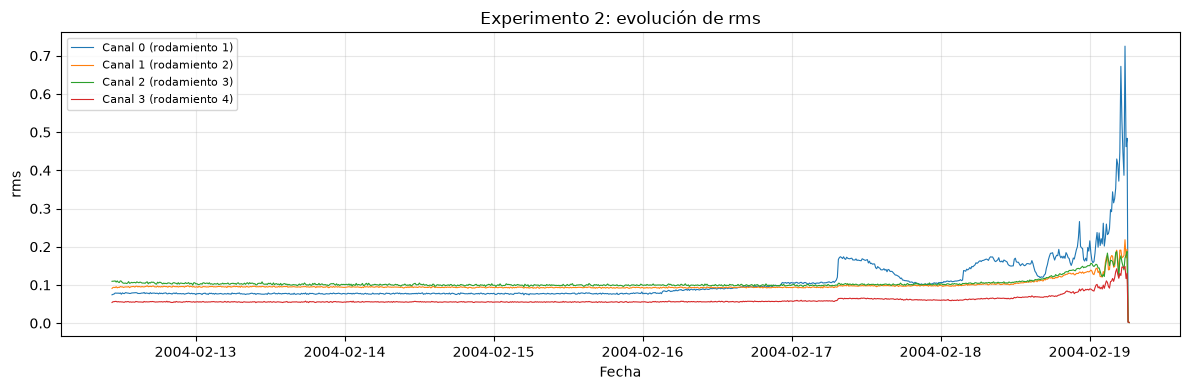

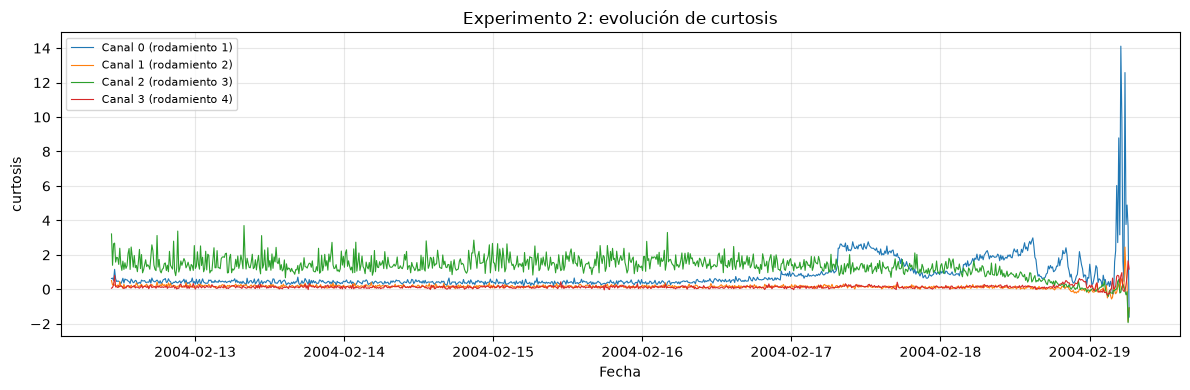

In [4]:
graficar_indicador("Experimento 2", "rms")
graficar_indicador("Experimento 2", "curtosis")

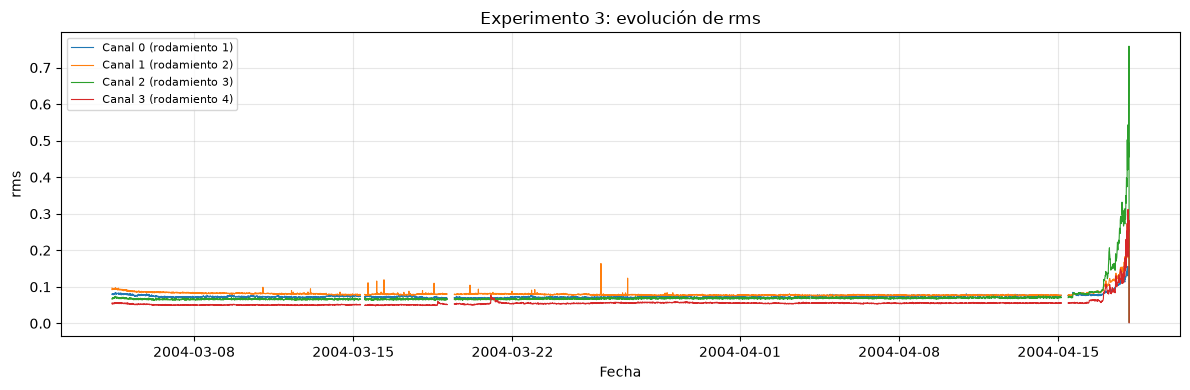

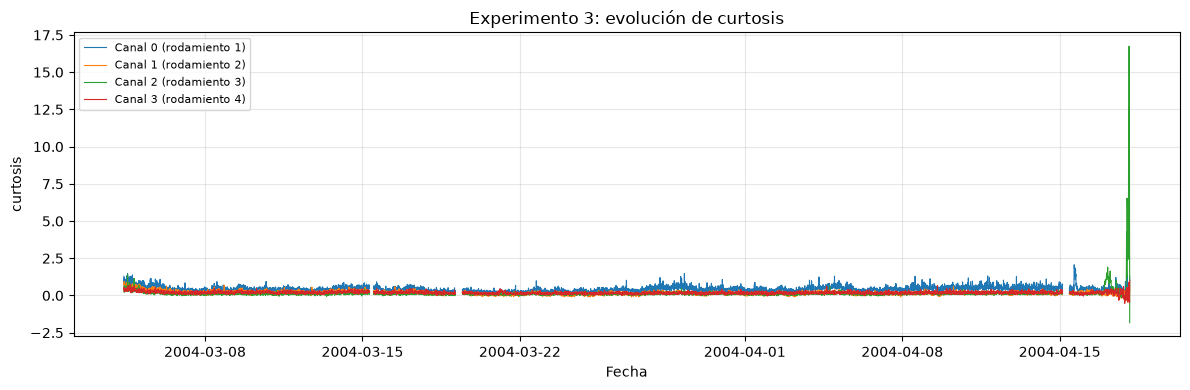

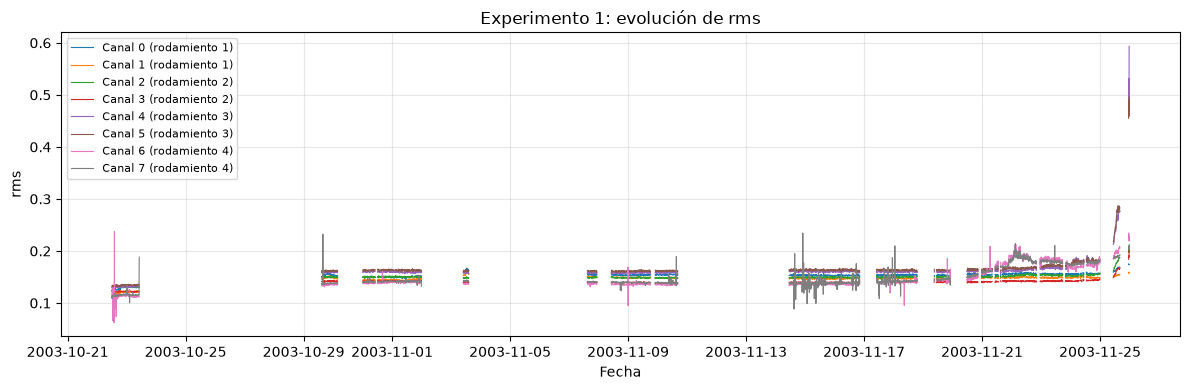

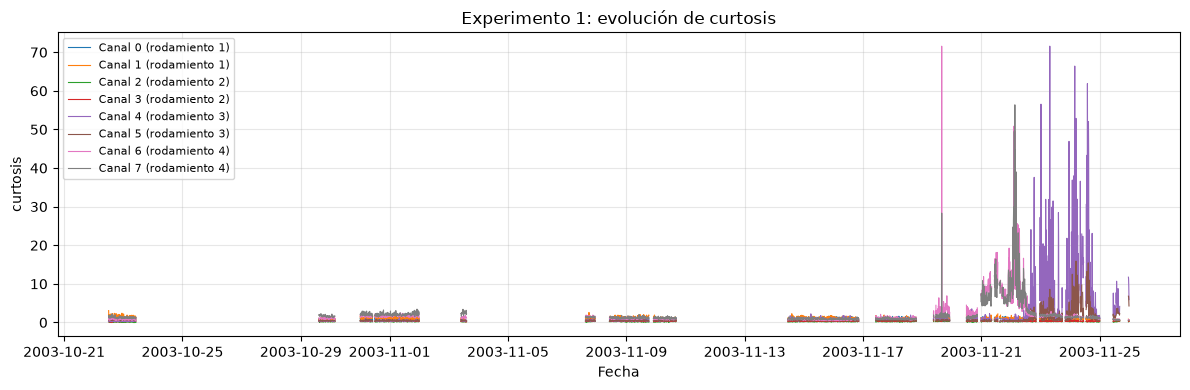

In [5]:
graficar_indicador("Experimento 3", "rms")
graficar_indicador("Experimento 3", "curtosis")
graficar_indicador("Experimento 1", "rms")
graficar_indicador("Experimento 1", "curtosis")

Los rodamientos se mantienen estables durante casi toda la prueba y la degradación aparece solo al final. En el experimento 2, el RMS del rodamiento 1 pasa de 0,08 a 0,72 (unas 9 veces) y su curtosis llega a 14. En el 3, la degradación del rodamiento 3 aparece solo en los últimos 2 a 3 días de 45, con RMS de 0,75 y curtosis de 16,5, lo que deja poco margen de aviso. Al final de cada prueba el RMS también sube en los rodamientos sanos por transmisión de la vibración, y cada sensor tiene su propio nivel de base.

### Por rodamiento

Se grafica un panel por rodamiento con escala vertical compartida, porque en el experimento 1 las 8 curvas superpuestas no se distinguían. Así se comparan directamente rodamientos sanos y dañados.

In [6]:
def graficar_por_rodamiento(experimento, indicador, umbral_pausa_min=30, escala_log=False, tabla=None):
    tabla = resumen if tabla is None else tabla
    datos = tabla[tabla["experimento"] == experimento].sort_values("fecha")
    columnas = [c for c in datos.columns
                if c.startswith(indicador + "_") and datos[c].notna().any()]
    canales_por_rod = 2 if len(columnas) == 8 else 1
    tramo = (datos["fecha"].diff() > pd.Timedelta(minutes=umbral_pausa_min)).cumsum()

    fig, ejes = plt.subplots(4, 1, figsize=(12, 10), sharex=True, sharey=True)
    for r, ax in enumerate(ejes):
        cols_rod = columnas[r * canales_por_rod:(r + 1) * canales_por_rod]
        for j, col in enumerate(cols_rod):
            for k, (_, datos_tramo) in enumerate(datos.groupby(tramo)):
                ax.plot(datos_tramo["fecha"], datos_tramo[col], linewidth=0.8,
                        color=f"C{j}", label=f"Canal {col.split('_')[1]}" if k == 0 else None)
        ax.set_title(f"Rodamiento {r + 1}", fontsize=10)
        ax.grid(alpha=0.3)
        ax.legend(loc="upper left", fontsize=8)
        if escala_log:
            ax.set_yscale("symlog")

    fig.suptitle(f"{experimento}: {indicador} por rodamiento")
    plt.tight_layout()
    plt.show()

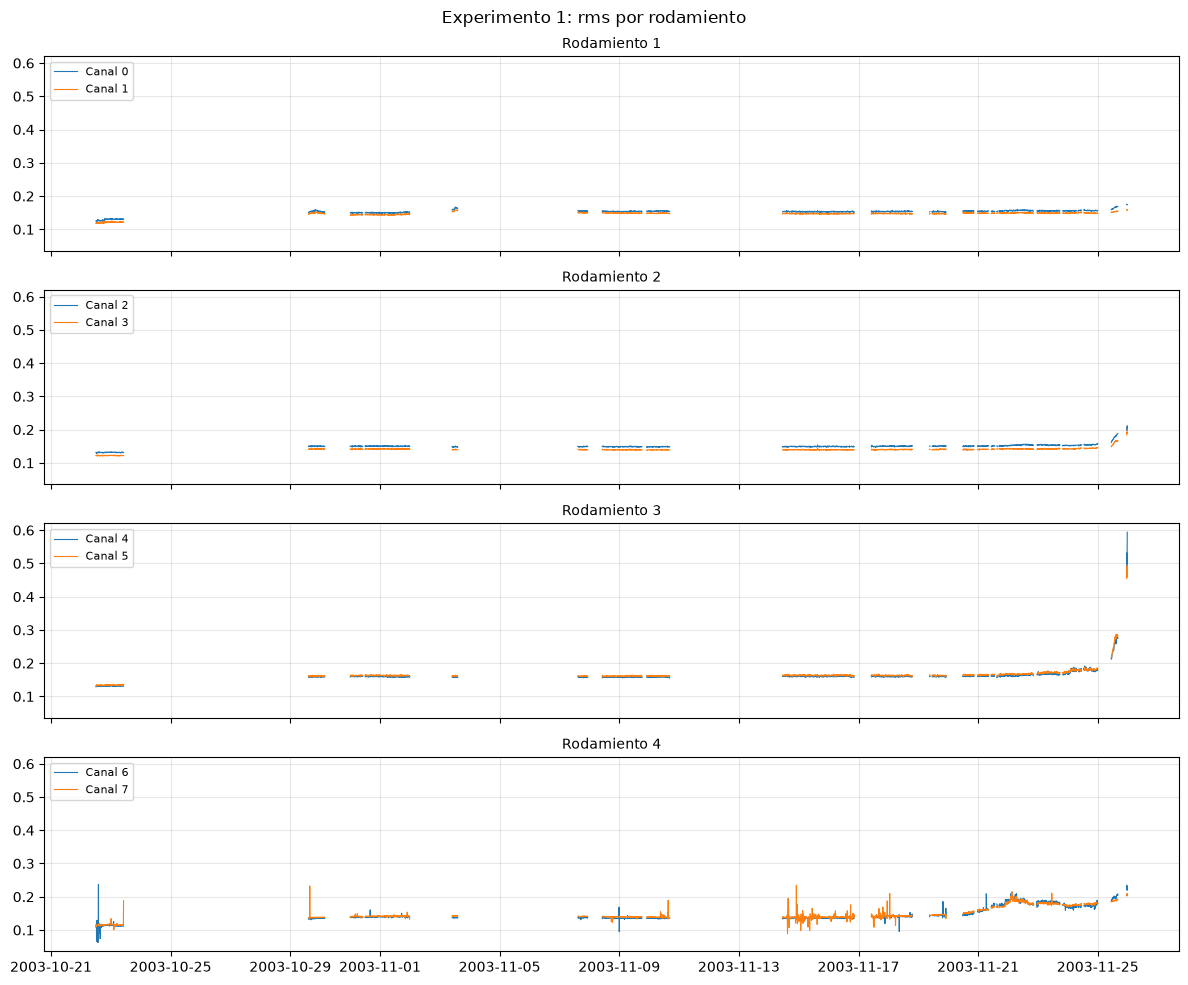

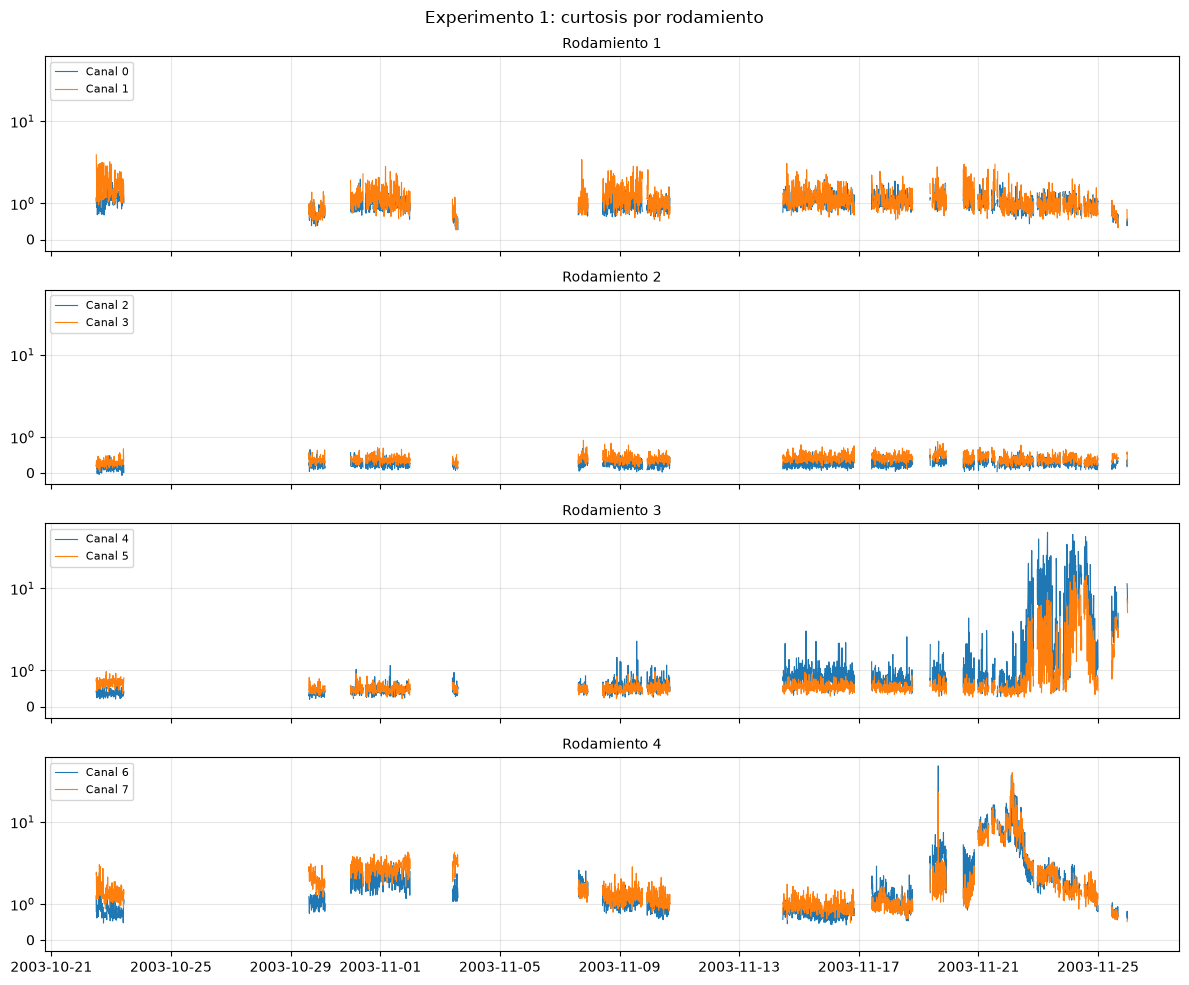

In [7]:
graficar_por_rodamiento("Experimento 1", "rms")
graficar_por_rodamiento("Experimento 1", "curtosis", escala_log=True)

En el experimento 1, los rodamientos 1 y 2 se mantienen estables. El rodamiento 3 se degrada de forma progresiva desde el 20 de noviembre hasta un RMS de 0,6. El rodamiento 4 muestra signos antes, desde el 18, y su curtosis sube hasta casi 50 y luego vuelve a valores normales cuando el daño es mayor: la curtosis no es monótona, así que detecta bien el daño incipiente pero no sirve sola para estimar el tiempo hasta la falla. Los primeros días del experimento son inestables, probablemente por el asentamiento de los rodamientos nuevos.

## 2. Señal cruda en distintos momentos de la prueba

Se muestran los primeros 100 ms de la señal del rodamiento 1 del experimento 2 al 0 %, 50 %, 97 % y 99 % de la prueba, con la misma escala, para ver qué cambia físicamente en la vibración. No se usa la última captura porque cae casi a cero.

In [8]:
def comparar_senales(experimento, canal, momentos=(0.0, 0.5, 0.97, 0.99), muestras=2000):
    carpeta = EXPERIMENTOS[experimento]
    archivos_exp = sorted(f for f in carpeta.iterdir() if f.is_file())

    fig, ejes = plt.subplots(len(momentos), 1, figsize=(12, 9), sharex=True, sharey=True)
    for ax, m in zip(ejes, momentos):
        f = archivos_exp[int(m * (len(archivos_exp) - 1))]
        x = pd.read_csv(f, sep="\t", header=None)[canal].values[:muestras]
        t = np.arange(len(x)) / 20000 * 1000   # tiempo en milisegundos (20 kHz)
        ax.plot(t, x, linewidth=0.6)
        ax.set_title(f"{f.name}  ({m:.0%} de la prueba)", fontsize=10)
        ax.grid(alpha=0.3)

    ejes[-1].set_xlabel("Tiempo (ms)")
    fig.suptitle(f"{experimento}, canal {canal}: señal cruda en distintos momentos")
    plt.tight_layout()
    plt.show()

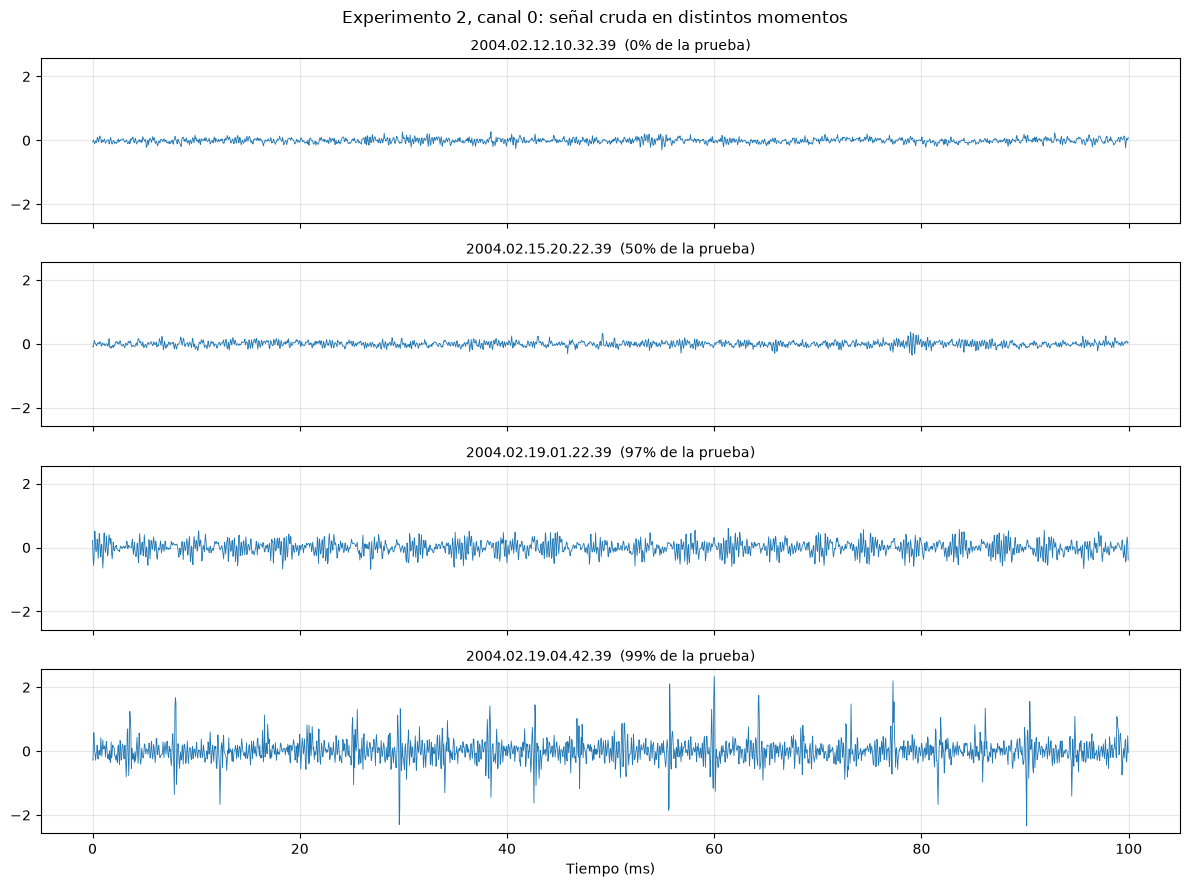

In [9]:
comparar_senales("Experimento 2", 0)

Al inicio y a la mitad, la señal es ruido pequeño y uniforme (±0,1 a 0,2). Al 97 % la amplitud crece a ±0,5. Al 99 % aparecen impactos de hasta ±2,3 que se repiten cada 4,3 ms aproximadamente (unos 230 Hz), lo que indica un defecto localizado y anticipa qué frecuencia buscar en el análisis espectral.

## 3. Análisis de envolvente

Se calculan las frecuencias teóricas de falla a partir de la geometría del rodamiento y la velocidad del eje, y se obtiene el espectro de envolvente: se filtra la señal entre 2 y 8 kHz (zona excitada por los impactos), se extrae su envolvente con la transformada de Hilbert y se calcula su espectro. Es la técnica estándar para diagnosticar rodamientos, porque convierte el ritmo de los impactos en un pico visible.

In [10]:
from scipy.signal import hilbert, butter, filtfilt

FS = 20000  # frecuencia de muestreo (Hz)

def frecuencias_falla(rpm=2000, n=16, d=0.331, D=2.815, angulo=15.17):
    """n: número de rodillos; d: diámetro del rodillo; D: diámetro primitivo (pulgadas)."""
    fr = rpm / 60
    r = (d / D) * np.cos(np.radians(angulo))
    return {
        "BPFO (pista externa)": n / 2 * fr * (1 - r),
        "BPFI (pista interna)": n / 2 * fr * (1 + r),
        "BSF (elemento rodante)": D / (2 * d) * fr * (1 - r**2),
        "FTF (jaula)": fr / 2 * (1 - r),
    }

FRECUENCIAS = frecuencias_falla()
for nombre, f in FRECUENCIAS.items():
    print(f"{nombre}: {f:.1f} Hz")

BPFO (pista externa): 236.4 Hz
BPFI (pista interna): 296.9 Hz
BSF (elemento rodante): 139.9 Hz
FTF (jaula): 14.8 Hz


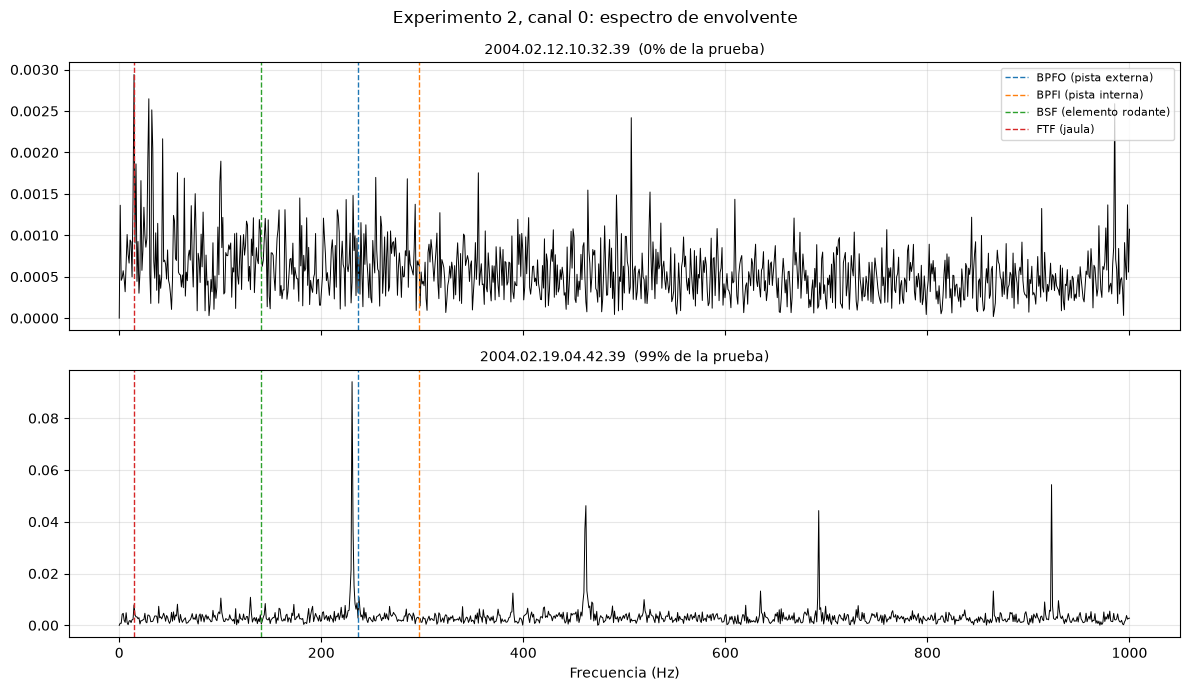

In [11]:
def espectro_envolvente(experimento, canal, momentos=(0.0, 0.99), fmax=1000, banda=(2000, 8000)):
    carpeta = EXPERIMENTOS[experimento]
    archivos_exp = sorted(f for f in carpeta.iterdir() if f.is_file())

    # Filtro pasabanda para aislar la zona de alta frecuencia excitada por los impactos
    b, a = butter(4, [banda[0] / (FS / 2), banda[1] / (FS / 2)], btype="band")

    fig, ejes = plt.subplots(len(momentos), 1, figsize=(12, 7), sharex=True)
    for ax, m in zip(ejes, momentos):
        f = archivos_exp[int(m * (len(archivos_exp) - 1))]
        x = pd.read_csv(f, sep="\t", header=None)[canal].values

        envolvente = np.abs(hilbert(filtfilt(b, a, x)))
        envolvente -= envolvente.mean()
        espectro = np.abs(np.fft.rfft(envolvente)) / len(envolvente)
        freqs = np.fft.rfftfreq(len(envolvente), 1 / FS)

        mascara = freqs <= fmax
        ax.plot(freqs[mascara], espectro[mascara], linewidth=0.7, color="black")
        for i, (nombre, fc) in enumerate(FRECUENCIAS.items()):
            ax.axvline(fc, color=f"C{i}", linestyle="--", linewidth=1,
                       label=nombre if ax is ejes[0] else None)
        ax.set_title(f"{f.name}  ({m:.0%} de la prueba)", fontsize=10)
        ax.grid(alpha=0.3)

    ejes[0].legend(fontsize=8, loc="upper right")
    ejes[-1].set_xlabel("Frecuencia (Hz)")
    fig.suptitle(f"{experimento}, canal {canal}: espectro de envolvente")
    plt.tight_layout()
    plt.show()

espectro_envolvente("Experimento 2", 0)

Las frecuencias teóricas son 236,4 Hz (pista externa), 296,9 Hz (pista interna), 139,9 Hz (elemento rodante) y 14,8 Hz (jaula). En el experimento 2, al inicio el espectro es solo ruido, y al final aparece un pico dominante cerca de 230 Hz con armónicos en 460, 690 y 920 Hz: la firma de un defecto en la pista externa, tal como reporta NASA. El pico queda un 2,5 % por debajo del teórico, lo cual es normal por el deslizamiento de los rodillos.

### Indicadores de envolvente por captura

Se construye un indicador por captura y canal: la amplitud del espectro de envolvente cerca de cada frecuencia de falla, sumando sus tres primeros armónicos y con una tolerancia de ±3 % para capturar el pico aunque esté corrido por el deslizamiento. Permite seguir en el tiempo cuándo aparece la firma de cada tipo de falla.

In [12]:
CODIGOS = {
    "bpfo": FRECUENCIAS["BPFO (pista externa)"],
    "bpfi": FRECUENCIAS["BPFI (pista interna)"],
    "bsf":  FRECUENCIAS["BSF (elemento rodante)"],
}

def amplitud_falla(espectro, freqs, fc, armonicos=3, tol=0.03):
    total = 0.0
    for k in range(1, armonicos + 1):
        ventana = (freqs >= k * fc * (1 - tol)) & (freqs <= k * fc * (1 + tol))
        total += espectro[ventana].max()
    return total

def indicadores_envolvente(experimento, banda=(2000, 8000)):
    b, a = butter(4, [banda[0] / (FS / 2), banda[1] / (FS / 2)], btype="band")
    archivos_exp = sorted(f for f in EXPERIMENTOS[experimento].iterdir() if f.is_file())
    filas = []

    for i, f in enumerate(archivos_exp, start=1):
        datos = pd.read_csv(f, sep="\t", header=None).values
        # Procesamos todos los canales a la vez (axis=0)
        envolvente = np.abs(hilbert(filtfilt(b, a, datos, axis=0), axis=0))
        envolvente -= envolvente.mean(axis=0)
        espectro = np.abs(np.fft.rfft(envolvente, axis=0)) / len(envolvente)
        freqs = np.fft.rfftfreq(len(envolvente), 1 / FS)

        fila = {"experimento": experimento,
                "fecha": pd.to_datetime(f.name, format="%Y.%m.%d.%H.%M.%S")}
        for c in range(datos.shape[1]):
            for codigo, fc in CODIGOS.items():
                fila[f"{codigo}_{c}"] = amplitud_falla(espectro[:, c], freqs, fc)
        filas.append(fila)

        if i % 500 == 0 or i == len(archivos_exp):
            print(f"{experimento}: {i}/{len(archivos_exp)}")

    return pd.DataFrame(filas)

In [13]:
# Se cargan desde data/interim si ya existen; si no, se calculan (puede tardar varios minutos)
envs = {}
for n in (1, 2, 3):
    ruta = INTERIM / f"envolvente_exp{n}.csv"
    if ruta.exists():
        envs[n] = pd.read_csv(ruta, parse_dates=["fecha"])
    else:
        envs[n] = indicadores_envolvente(f"Experimento {n}")
        envs[n].to_csv(ruta, index=False)
env1, env2, env3 = envs[1], envs[2], envs[3]

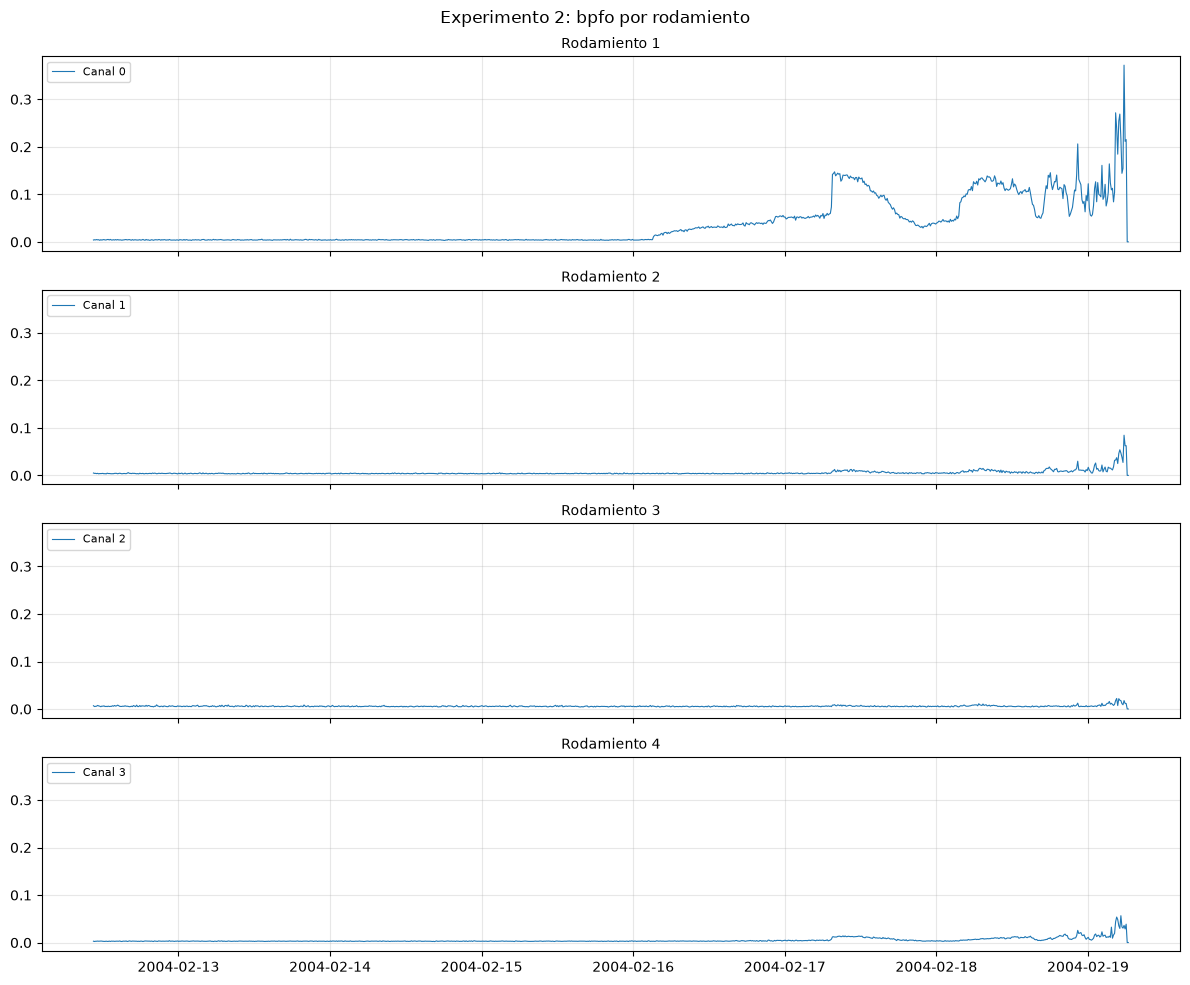

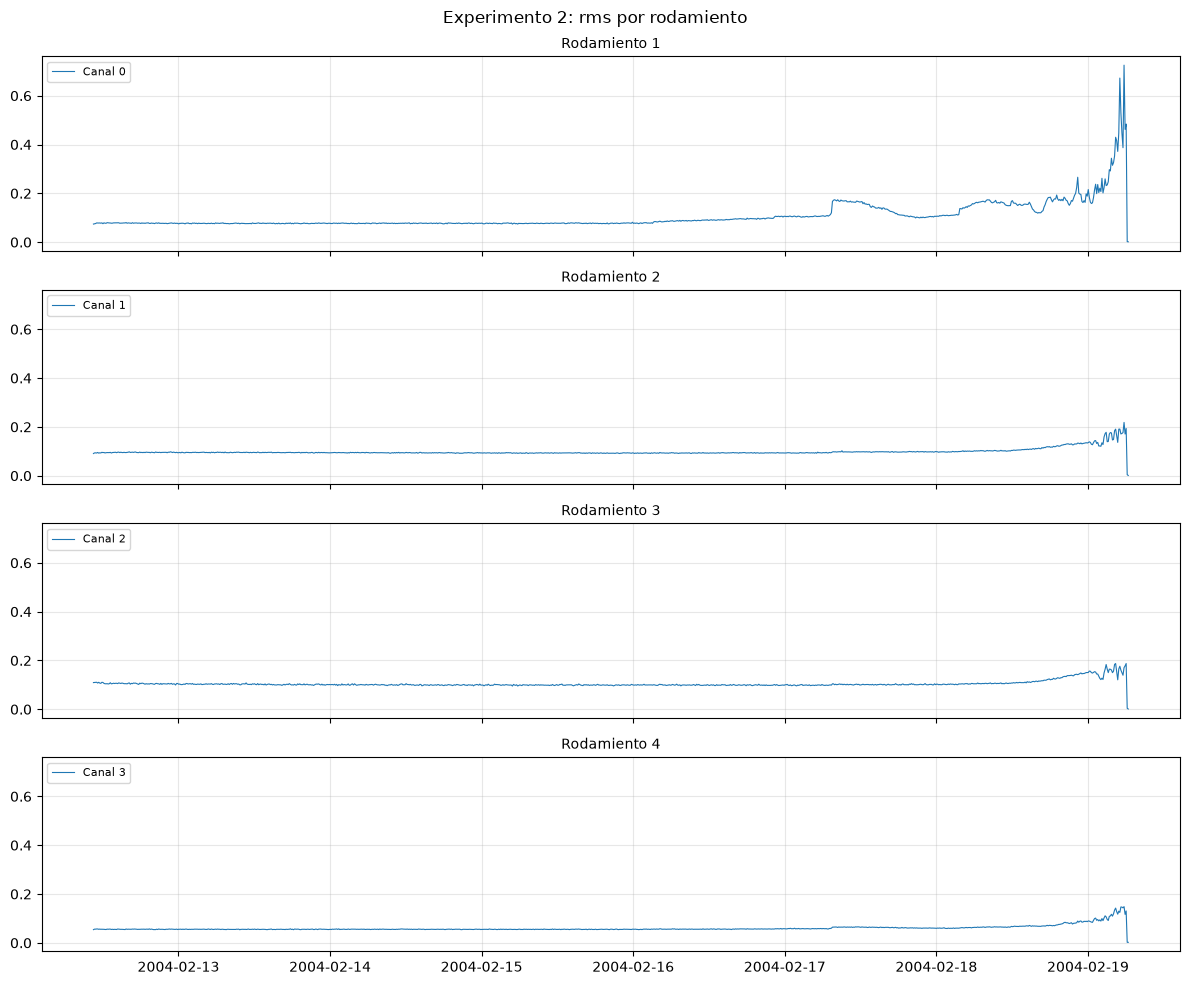

In [14]:
graficar_por_rodamiento("Experimento 2", "bpfo", tabla=env2)
graficar_por_rodamiento("Experimento 2", "rms")

En el experimento 2, el indicador de pista externa del rodamiento 1 sube de 0,005 a 0,03 (entre 4 y 6 veces) el 16 de febrero, mientras el RMS apenas sube un 10 a 15 %. Además es selectivo: se dispara solo en el rodamiento dañado, mientras el RMS sube en todos. En los otros experimentos se confirman los tipos de falla reportados: pista externa en el rodamiento 3 del experimento 3, y pista interna y elemento rodante en los rodamientos 3 y 4 del experimento 1.

## 4. Tiempos de detección

Se aplica una regla objetiva para comparar qué indicador detecta antes el daño: umbral igual a la media más tres desviaciones estándar del periodo de referencia, superado en tres capturas consecutivas para evitar falsas alarmas por picos aislados. Se aplica también a los rodamientos sanos para medir las falsas alarmas.

In [15]:
def fecha_deteccion(tabla, experimento, columna, horas_base=24, k=3, consecutivas=3, inicio_base=None):
    d = tabla[tabla["experimento"] == experimento].sort_values("fecha")
    if inicio_base is not None:
        d = d[d["fecha"] >= pd.Timestamp(inicio_base)]
    d = d.reset_index(drop=True)

    base = d.loc[d["fecha"] <= d["fecha"].iloc[0] + pd.Timedelta(hours=horas_base), columna]
    umbral = base.mean() + k * base.std()

    sobre = d[columna] > umbral
    racha = sobre.rolling(consecutivas).sum() == consecutivas
    if not racha.any():
        return None
    return d.loc[racha.idxmax() - consecutivas + 1, "fecha"]

def comparar_deteccion(experimento, canal, tabla_env, **opciones):
    fin = resumen.loc[resumen["experimento"] == experimento, "fecha"].max()
    indicadores = {
        "RMS": (resumen, f"rms_{canal}"),
        "Curtosis": (resumen, f"curtosis_{canal}"),
        "BPFO": (tabla_env, f"bpfo_{canal}"),
        "BPFI": (tabla_env, f"bpfi_{canal}"),
        "BSF": (tabla_env, f"bsf_{canal}"),
    }
    filas = []
    for nombre, (tabla, col) in indicadores.items():
        fecha = fecha_deteccion(tabla, experimento, col, **opciones)
        filas.append({
            "indicador": nombre,
            "fecha de detección": fecha,
            "horas antes del final": None if fecha is None else round((fin - fecha).total_seconds() / 3600, 1),
        })
    return pd.DataFrame(filas).set_index("indicador")

def tabla_deteccion(experimento, tabla_env, **opciones):
    canales = [int(c.split("_")[1]) for c in tabla_env.columns
               if c.startswith("bpfo_") and tabla_env[c].notna().any()]
    filas = {f"Canal {c}": comparar_deteccion(experimento, c, tabla_env, **opciones)["horas antes del final"]
             for c in canales}
    return pd.DataFrame(filas).T

In [16]:
comparar_deteccion("Experimento 2", 0, env2)

,fecha de detección,horas antes del final
indicador,,
RMS,2004-02-16 03:12:39,75.2
Curtosis,2004-02-16 22:22:39,56.0
BPFO,2004-02-16 03:12:39,75.2
BPFI,2004-02-16 14:22:39,64.0
BSF,2004-02-17 07:12:39,47.2


In [17]:
tabla_deteccion("Experimento 2", env2)

indicador,RMS,Curtosis,BPFO,BPFI,BSF
Canal 0,75.2,56.0,75.2,64.0,47.2
Canal 1,34.7,NaN,47.0,1.5,NaN
Canal 2,15.3,NaN,24.3,NaN,NaN
Canal 3,54.7,10.3,55.7,46.3,3.7


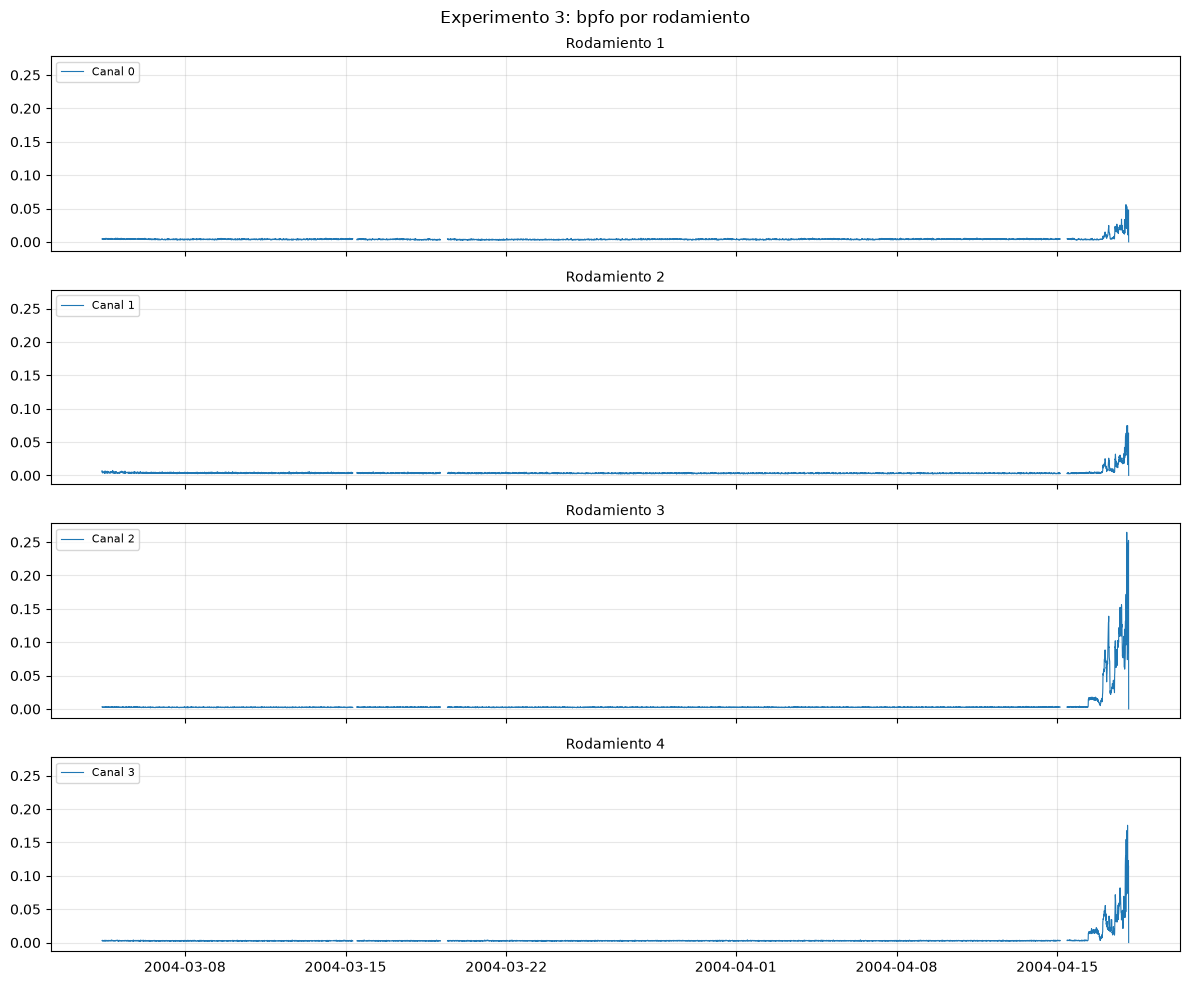

indicador,RMS,Curtosis,BPFO,BPFI,BSF
Canal 0,25.2,59.3,26.8,11.3,NaN
Canal 1,26.8,NaN,27.0,17.0,4.8
Canal 2,59.3,25.5,42.3,38.8,27.0
Canal 3,729.6,NaN,42.3,44.8,24.0


In [18]:
graficar_por_rodamiento("Experimento 3", "bpfo", tabla=env3)
tabla_deteccion("Experimento 3", env3)

In [19]:
tabla_deteccion("Experimento 1", env1, inicio_base="2003-10-29 14:39", horas_base=48)

indicador,RMS,Curtosis,BPFO,BPFI,BSF
Canal 0,540.5,NaN,94.5,90.4,83.5
Canal 1,539.8,NaN,269.4,104.5,539.0
Canal 2,92.9,NaN,81.9,83.4,84.0
Canal 3,28.4,NaN,25.2,25.0,12.2
Canal 4,263.0,276.5,71.7,124.7,239.2
Canal 5,108.5,79.7,78.7,71.5,45.6
Canal 6,204.8,156.4,228.0,594.1,582.1
Canal 7,109.2,120.0,153.1,120.0,125.9


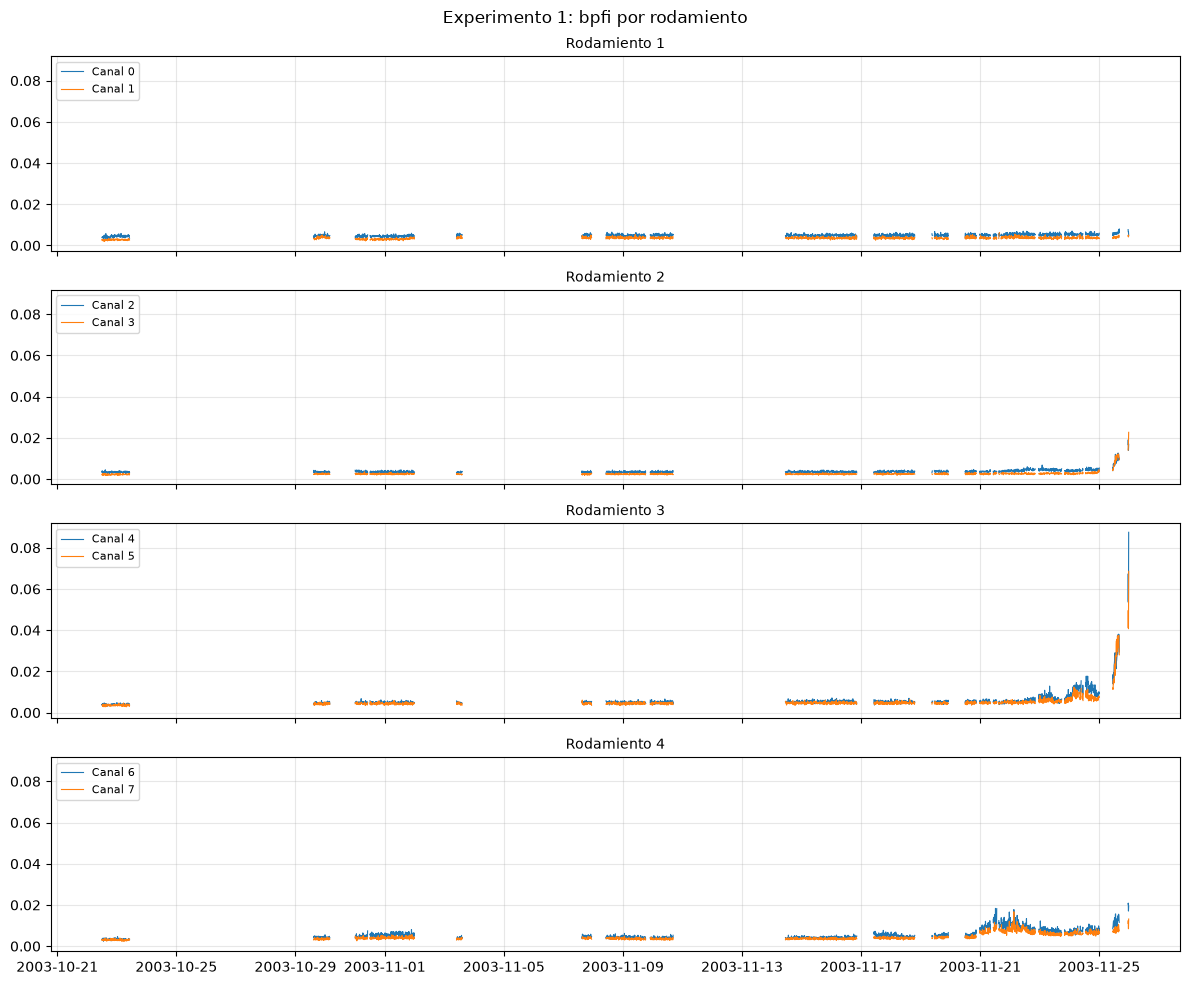

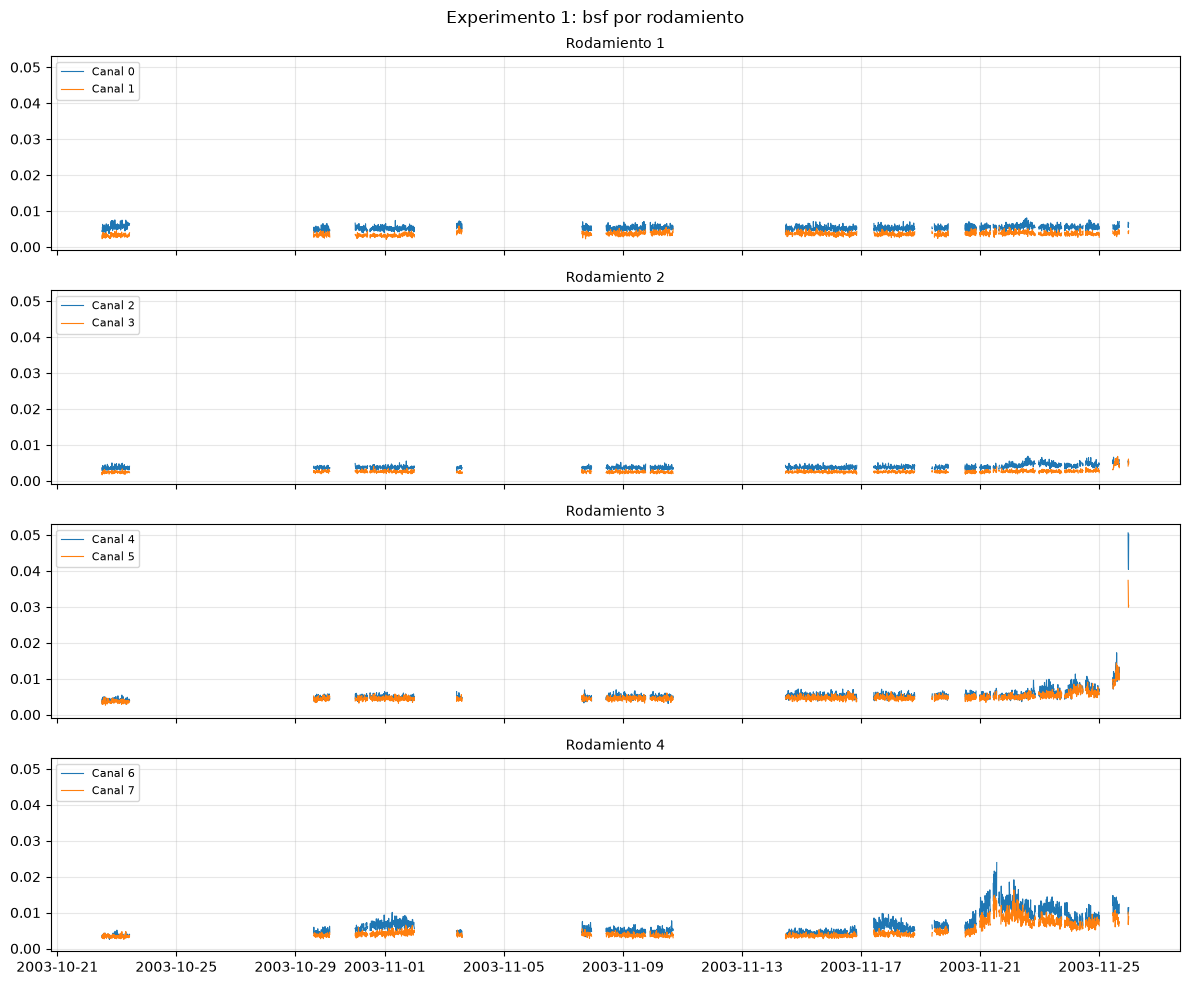

In [20]:
graficar_por_rodamiento("Experimento 1", "bpfi", tabla=env1)
graficar_por_rodamiento("Experimento 1", "bsf", tabla=env1)

En el experimento 2, el RMS y el indicador de pista externa detectan a la vez, 75 horas antes de la falla, y la curtosis 56 horas antes; la ventaja del análisis de envolvente aquí es la claridad y la selectividad, no la anticipación. En el experimento 3, el indicador de pista externa detecta 42 horas antes frente a 25 del RMS, unas 17 horas de ventaja. En ambos, el rodamiento dañado es siempre el primero en cruzar el umbral. En el experimento 1 la regla no es confiable: con las primeras 24 horas como referencia, casi todos los canales detectan justo al reanudar tras la primera pausa (asentamiento), y aun cambiando la referencia aparecen falsas alarmas por los cambios de nivel al reanudar cada pausa. Se necesitan métodos más robustos que un umbral fijo.

## 5. Etiquetado provisional y balance de clases

Se asigna a cada captura de cada rodamiento un estado provisional (sano, degradado o excluido) para poder cuantificar el balance de clases. En los experimentos 2 y 3, el inicio de la degradación se toma de la regla de detección con el indicador de pista externa, que fue el más claro; en el experimento 1, donde la regla no es confiable, se fija por inspección visual de las gráficas. Se excluyen las capturas planas y el periodo de asentamiento del experimento 1. El resultado se guarda en `data/interim/etiquetas_provisionales.csv`.

In [21]:
# Inicio provisional de la degradación de cada rodamiento que falló
INICIO_DEGRADACION = {
    ("Experimento 2", 1): fecha_deteccion(env2, "Experimento 2", "bpfo_0"),  # regla de detección
    ("Experimento 3", 3): fecha_deteccion(env3, "Experimento 3", "bpfo_2"),  # regla de detección
    ("Experimento 1", 3): pd.Timestamp("2003-11-20"),  # visual: crecimiento sostenido de RMS y BPFI
    ("Experimento 1", 4): pd.Timestamp("2003-11-18"),  # visual: inicio de la subida de curtosis y BSF
}

# Capturas que no se usan (ver notebook 02 y sección 4)
CAPTURAS_PLANAS = ["2004.02.19.06.12.39", "2004.02.19.06.22.39", "2004.04.18.02.42.55"]
FIN_ASENTAMIENTO_EXP1 = pd.Timestamp("2003-10-29 14:39")

fin = resumen.groupby("experimento")["fecha"].max()

# Una fila por captura y rodamiento
etiquetas = pd.concat(
    [resumen[["experimento", "archivo", "fecha"]].assign(rodamiento=rod) for rod in range(1, 5)],
    ignore_index=True,
)
etiquetas["estado"] = "sano"
for (exp, rod), inicio in INICIO_DEGRADACION.items():
    m = (etiquetas["experimento"] == exp) & (etiquetas["rodamiento"] == rod) & (etiquetas["fecha"] >= inicio)
    etiquetas.loc[m, "estado"] = "degradado"

excluir = etiquetas["archivo"].isin(CAPTURAS_PLANAS) | (
    (etiquetas["experimento"] == "Experimento 1") & (etiquetas["fecha"] < FIN_ASENTAMIENTO_EXP1)
)
etiquetas.loc[excluir, "estado"] = "excluido"
etiquetas["horas_hasta_fin"] = (etiquetas["experimento"].map(fin) - etiquetas["fecha"]).dt.total_seconds() / 3600
etiquetas.to_csv(INTERIM / "etiquetas_provisionales.csv", index=False)

inicios = pd.DataFrame([
    {"experimento": e, "rodamiento": r, "inicio de degradación": f,
     "horas antes del final": round((fin[e] - f).total_seconds() / 3600, 1)}
    for (e, r), f in INICIO_DEGRADACION.items()
])
display(inicios)

,experimento,rodamiento,inicio de degradación,horas antes del final
0,Experimento 2,1,2004-02-16 03:12:39,75.2
1,Experimento 3,3,2004-04-16 08:22:55,42.3
2,Experimento 1,3,2003-11-20 00:00:00,143.7
3,Experimento 1,4,2003-11-18 00:00:00,191.7


In [22]:
validas = etiquetas[etiquetas["estado"] != "excluido"]

balance = validas.groupby(["experimento", "estado"]).size().unstack(fill_value=0)
balance["% degradado"] = (100 * balance["degradado"] / balance[["sano", "degradado"]].sum(axis=1)).round(1)
total = balance[["sano", "degradado"]].sum()
balance.loc["Total"] = [total["degradado"], total["sano"], round(100 * total["degradado"] / total.sum(), 1)] if list(balance.columns[:2]) == ["degradado", "sano"] else [total["sano"], total["degradado"], round(100 * total["degradado"] / total.sum(), 1)]
display(balance)

# Solo los rodamientos que fallaron
fallados = validas.merge(pd.DataFrame(list(INICIO_DEGRADACION.keys()), columns=["experimento", "rodamiento"]))
bal_f = fallados.groupby(["experimento", "rodamiento", "estado"]).size().unstack(fill_value=0)
bal_f["% degradado"] = (100 * bal_f["degradado"] / bal_f[["sano", "degradado"]].sum(axis=1)).round(1)
display(bal_f)

estado,degradado,sano,% degradado
experimento,,,
Experimento 1,1486.0,6514.0,18.6
Experimento 2,450.0,3478.0,11.5
Experimento 3,254.0,25038.0,1.0
Total,2190.0,35030.0,5.9


estado                    degradado  sano  % degradado
experimento   rodamiento                              
Experimento 1 3                 649  1351         32.4
              4                 837  1163         41.8
Experimento 2 1                 450   532         45.8
Experimento 3 3                 254  6069          4.0

Las fechas provisionales de inicio de la degradación quedan 75 horas antes del final en el rodamiento 1 del experimento 2 y 42 horas antes en el rodamiento 3 del experimento 3 (ambas por la regla de detección), y 144 y 192 horas antes en los rodamientos 3 y 4 del experimento 1 (por inspección visual).

Con estas fechas, el conjunto está **fuertemente desbalanceado**: de 37.220 pares captura-rodamiento válidos, solo 2.190 (5,9 %) quedan como degradados. El desbalance varía mucho entre experimentos: 18,6 % de capturas degradadas en el experimento 1, 11,5 % en el 2 y apenas 1,0 % en el 3. Incluso mirando solo los rodamientos que fallaron, la proporción va del 4,0 % (rodamiento 3 del experimento 3) al 45,8 % (rodamiento 1 del experimento 2). Paradójicamente, el experimento más largo es el que menos ejemplos de degradación aporta.

Implicaciones para el modelado: la exactitud (accuracy) sería engañosa, porque un modelo que dijera siempre "sano" acertaría el 94 % de las veces; habrá que evaluar con métricas como la sensibilidad sobre la clase degradada, el F1 y las matrices de confusión, y considerar ponderación de clases o remuestreo aplicados solo al conjunto de entrenamiento. Las etiquetas son provisionales y el balance depende de las fechas de inicio, sobre todo en el experimento 1.

## 6. Distribución de los datos

Se compara la distribución de la amplitud de la señal en una captura sana y una degradada, y la distribución de los indicadores RMS, curtosis y pista externa en cada estado, para los rodamientos que fallaron. Esto muestra si los estados se separan bien y qué forma tienen las distribuciones, lo que orienta la normalización y la elección de modelos.

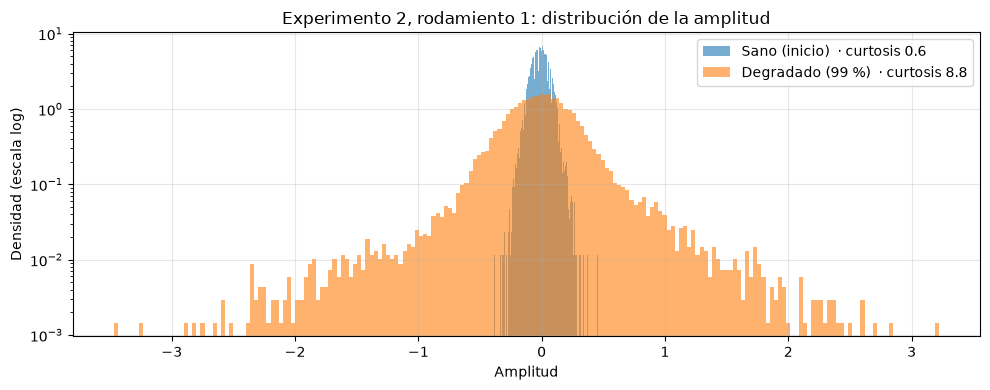

In [23]:
# Distribución de la amplitud de la señal: rodamiento 1 del experimento 2, sano vs. degradado
archivos2 = sorted(f for f in EXPERIMENTOS["Experimento 2"].iterdir() if f.is_file())
sano = pd.read_csv(archivos2[0], sep="\t", header=None)[0]
degradado = pd.read_csv(archivos2[int(0.99 * (len(archivos2) - 1))], sep="\t", header=None)[0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sano, bins=200, density=True, alpha=0.6, label=f"Sano (inicio)  · curtosis {sano.kurt():.1f}")
ax.hist(degradado, bins=200, density=True, alpha=0.6, label=f"Degradado (99 %)  · curtosis {degradado.kurt():.1f}")
ax.set_yscale("log")
ax.set_xlabel("Amplitud")
ax.set_ylabel("Densidad (escala log)")
ax.set_title("Experimento 2, rodamiento 1: distribución de la amplitud")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

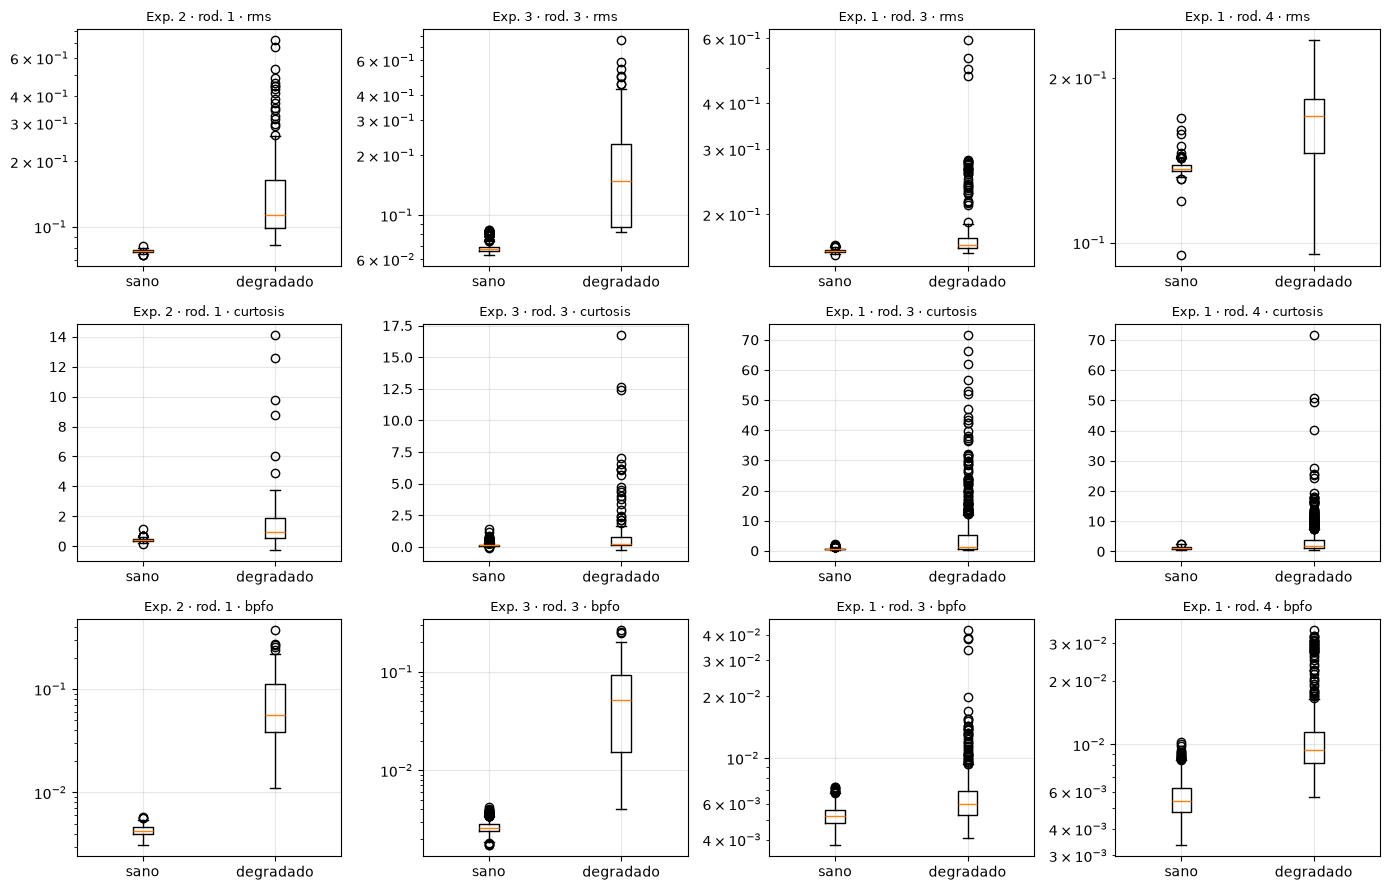

n  mediana   media  desv. estándar  \
caso            indicador estado                                             
Exp. 2 · rod. 1 rms       sano        532   0.0773  0.0773          0.0011   
                          degradado   450   0.1128  0.1407          0.0720   
                curtosis  sano        532   0.4103  0.4184          0.0944   
                          degradado   450   0.9265  1.3106          1.2528   
                bpfo      sano        532   0.0043  0.0043          0.0005   
                          degradado   450   0.0557  0.0764          0.0476   
Exp. 3 · rod. 3 rms       sano       6069   0.0677  0.0680          0.0027   
                          degradado   254   0.1477  0.1774          0.1091   
                curtosis  sano       6069   0.1149  0.1246          0.0767   
                          degradado   254   0.2268  0.8023          1.8587   
                bpfo      sano       6069   0.0026  0.0026          0.0003   
                          degradado   254   0.0515  0.0600          0.0501   
Exp. 1 · rod. 3 rms       sano       1351   0.1596  0.1597          0.0015   
                          degradado   649   0.1649  0.1737          0.0345   
                curtosis  sano       1351   0.5751  0.6318          0.2508   
                          degradado   649   1.1380  5.1664          9.2931   
                bpfo      sano       1351   0.0052  0.0052          0.0006   
                          degradado   649   0.0060  0.0066          0.0031   
Exp. 1 · rod. 4 rms       sano       1163   0.1363  0.1370          0.0029   
                          degradado   837   0.1706  0.1669          0.0197   
                curtosis  sano       1163   1.0720  1.1566          0.4061   
                          degradado   837   1.7813  3.6509          5.1545   
                bpfo      sano       1163   0.0054  0.0056          0.0011   
                          degradado   837   0.0094  0.0106          0.0045   

                                     asimetría  
caso            indicador estado                
Exp. 2 · rod. 1 rms       sano          0.0650  
                          degradado     3.8731  
                curtosis  sano          1.2205  
                          degradado     5.4049  
                bpfo      sano          0.2526  
                          degradado     1.3382  
Exp. 3 · rod. 3 rms       sano          1.9560  
                          degradado     1.6874  
                curtosis  sano          2.9292  
                          degradado     5.2649  
                bpfo      sano          0.4966  
                          degradado     1.1563  
Exp. 1 · rod. 3 rms       sano          0.3444  
                          degradado     7.5011  
                curtosis  sano          1.4879  
                          degradado     3.4620  
                bpfo      sano          0.3193  
                          degradado     6.9878  
Exp. 1 · rod. 4 rms       sano         -0.4655  
                          degradado     0.0617  
                curtosis  sano          0.6030  
                          degradado     5.8430  
                bpfo      sano          0.8560  
                          degradado     2.9525

In [24]:
# Distribución de los indicadores por estado en los rodamientos que fallaron
TABLAS_ENV = {"Experimento 1": env1, "Experimento 2": env2, "Experimento 3": env3}

def valores_rodamiento(exp, rod, indicador):
    tabla = TABLAS_ENV[exp] if indicador in ("bpfo", "bpfi", "bsf") else resumen
    canal = (rod - 1) * 2 if exp == "Experimento 1" else rod - 1
    col = f"{indicador}_{canal}"
    d = tabla.loc[tabla["experimento"] == exp, ["fecha", col]].rename(columns={col: "valor"})
    e = etiquetas.loc[(etiquetas["experimento"] == exp) & (etiquetas["rodamiento"] == rod), ["fecha", "estado"]]
    return d.merge(e, on="fecha").query("estado != 'excluido'")

casos = list(INICIO_DEGRADACION.keys())
indicadores = ["rms", "curtosis", "bpfo"]
fig, ejes = plt.subplots(len(indicadores), len(casos), figsize=(14, 9))
estadisticas = []
for j, (exp, rod) in enumerate(casos):
    for i, ind in enumerate(indicadores):
        v = valores_rodamiento(exp, rod, ind)
        grupos = [v.loc[v["estado"] == s, "valor"] for s in ("sano", "degradado")]
        ax = ejes[i, j]
        ax.boxplot(grupos)
        ax.set_xticks([1, 2], ["sano", "degradado"])
        if ind != "curtosis":
            ax.set_yscale("log")
        ax.set_title(f"Exp. {exp[-1]} · rod. {rod} · {ind}", fontsize=9)
        ax.grid(alpha=0.3)
        for s, g in zip(("sano", "degradado"), grupos):
            estadisticas.append({"caso": f"Exp. {exp[-1]} · rod. {rod}", "indicador": ind, "estado": s,
                                 "n": len(g), "mediana": g.median(), "media": g.mean(),
                                 "desv. estándar": g.std(), "asimetría": g.skew()})
plt.tight_layout()
plt.show()

display(pd.DataFrame(estadisticas).set_index(["caso", "indicador", "estado"]).round(4))

**Amplitud de la señal.** 
En la captura sana, la amplitud se concentra en una distribución estrecha y casi simétrica (desviación estándar de 0,074, valores entre −0,39 y 0,45, curtosis de 0,63, cercana a la de una distribución normal). En la captura degradada, la dispersión es cinco veces mayor (desviación estándar de 0,37), los valores llegan a ±3,4 y la curtosis sube a 8,8: aparecen colas largas producidas por los impactos del defecto, que en la escala logarítmica se ven como extremos mucho más frecuentes.

**Indicadores por estado.** 
En estado sano, los indicadores están muy concentrados (por ejemplo, el RMS varía apenas entre 0,001 y 0,003 de desviación estándar) y son casi simétricos. En estado degradado se vuelven mucho más dispersos y asimétricos hacia la derecha, con asimetrías de hasta 7,5. Las distribuciones no son normales y tienen colas largas, lo que sugiere usar escalamientos robustos (basados en mediana y rango intercuartílico) o transformaciones logarítmicas en la Fase III.

**Separación entre estados.** 
En los experimentos 2 y 3 los estados se separan con claridad, sobre todo con el indicador de pista externa: su mediana pasa de 0,0043 a 0,0557 (13 veces) en el experimento 2 y de 0,0026 a 0,0515 (20 veces) en el 3, una separación mucho mayor que la del RMS (de 0,077 a 0,113 y de 0,068 a 0,148). En el experimento 1, en cambio, la separación de las medianas es débil (en el rodamiento 3, el RMS pasa de 0,160 a 0,165 y la pista externa de 0,0052 a 0,0060), lo que indica que el periodo marcado como degradado incluye mucho tiempo con cambios pequeños. Esto refuerza que las fechas de inicio del experimento 1 deben revisarse y que una etiqueta binaria sano/degradado puede ser demasiado gruesa; un indicador de salud continuo o etapas de degradación podrían representar mejor el proceso.

## 7. Redundancia entre sensores e indicadores

Se mide la correlación de Spearman (que capta relaciones crecientes aunque no sean lineales y es robusta a valores extremos) entre los dos sensores de cada rodamiento del experimento 1, y entre los distintos indicadores. Una correlación muy alta indica información redundante, lo que justifica conservar menos variables.

In [25]:
# Correlación (Spearman) entre los dos sensores de cada rodamiento del experimento 1
r1 = resumen[resumen["experimento"] == "Experimento 1"].reset_index(drop=True)
e1 = env1.sort_values("fecha").reset_index(drop=True)
filas = []
for rod in range(1, 5):
    a, b = 2 * (rod - 1), 2 * (rod - 1) + 1
    fila = {"rodamiento": rod}
    for ind, tabla in [("rms", r1), ("curtosis", r1), ("bpfo", e1), ("bpfi", e1), ("bsf", e1)]:
        fila[ind] = tabla[f"{ind}_{a}"].corr(tabla[f"{ind}_{b}"], method="spearman")
    filas.append(fila)
pd.DataFrame(filas).set_index("rodamiento").round(2)

,rms,curtosis,bpfo,bpfi,bsf
rodamiento,,,,,
1,0.87,0.39,0.36,0.37,0.20
2,0.86,0.40,0.29,0.34,0.28
3,0.91,0.48,0.49,0.57,0.52
4,0.89,0.78,0.82,0.83,0.83


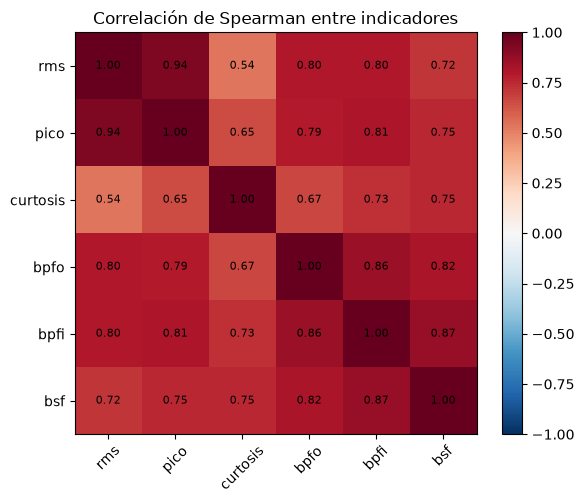

In [26]:
# Correlación (Spearman) entre indicadores, juntando todos los rodamientos
partes = []
for exp, tabla_env in TABLAS_ENV.items():
    r = resumen[resumen["experimento"] == exp].merge(tabla_env, on=["experimento", "fecha"])
    canales = range(0, 8, 2) if exp == "Experimento 1" else range(4)
    for c in canales:
        partes.append(pd.DataFrame({k: r[f"{k}_{c}"] for k in ["rms", "pico", "curtosis", "bpfo", "bpfi", "bsf"]}))
indicadores_df = pd.concat(partes, ignore_index=True)
corr = indicadores_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for k in range(len(corr)):
        ax.text(k, i, f"{corr.iloc[i, k]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlación de Spearman entre indicadores")
plt.tight_layout()
plt.show()

**Sensores del experimento 1.** 
El RMS de los dos sensores de cada rodamiento está muy correlacionado (entre 0,86 y 0,91), así que para medir la energía de la vibración basta con uno. Pero en la curtosis y en los indicadores de envolvente la correlación es baja en los rodamientos sanos (entre 0,20 y 0,40), donde la señal está dominada por ruido, y solo sube en los rodamientos que fallaron (alrededor de 0,5 en el 3 y de 0,8 en el 4). Es decir, el segundo sensor no es del todo redundante para las características impulsivas y de frecuencia: conviene conservar ambos o combinarlos (por ejemplo, con su promedio o su máximo) en lugar de descartar uno.

**Indicadores.** 
El RMS y el pico están casi duplicados (correlación de 0,94), por lo que basta con conservar uno, preferiblemente el RMS, que es más estable. Los tres indicadores de envolvente están muy correlacionados entre sí (entre 0,82 y 0,87) y con el RMS (alrededor de 0,8), porque cuando el rodamiento se degrada toda la vibración aumenta; aun así, aportan la información sobre el tipo de falla, que se obtiene de cuál crece más, y no conviene descartarlos. La curtosis es el indicador menos correlacionado con los demás (entre 0,54 y 0,75), así que aporta información complementaria, ligada a los impactos del daño incipiente.

En síntesis, para la construcción de características se recomienda conservar el RMS, la curtosis y los indicadores de envolvente, y prescindir del pico. Hay que tener en cuenta que estas correlaciones se calcularon juntando todos los rodamientos y periodos, de modo que están influidas por el predominio de capturas sanas.